# TP Outils Mathématiques - Analyse de Fourier sur des sons

# NOMS du binôme : Julcinia OKE, IHOGOZA Kedia, DEGUENON Fidel 

La **transformée de Fourier** est un formidable outil d’analyse des signaux musicaux. On la rencontre notamment pour ce qui concerne le filtrage, le traitement, la synthèse de sons, etc. 
Une manifestation simple du spectre de Fourier peut être facilement obtenue avec une chaîne Hi-Fi, ou avec un logiciel de lecture de sons. En effet, les barres qui évoluent en fonction du temps quand on lit un morceau de musique n’est rien d’autre que le spectre de Fourier du son qui est en train d’être joué !


L’analyse spectrale d’un signal consiste à trouver toutes les sinusoïdes qui contribuent significativement au signal : cela veut dire identifier les **fréquences** et les **amplitudes** des sinusoïdes associées. Un **spectre de Fourier, ou spectre fréquentiel**, est une représentation graphique permettant de visualiser ces deux grandeurs, où les fréquences sont en abscisses et les amplitudes en ordonnées.


Après, *en musique*, certains termes spécifiques sont utilisés afin d’évoquer les notions que nous venons de voir. Notamment :

• La **hauteur d’un son** désigne la **fréquence fondamentale** d’un son musical. Notons que la plupart des instruments de musique émettent des sons complexes. En musique, il y a une correspondance entre le nom d’une note (do, ré, mi, …) et sa hauteur (fréquence). Par exemple, le son du diapason est le *la* international de fréquence 440 Hz.

. un **harmonique**  est en acoustique une des composantes d’un son complexe. Dans la nature, lorsqu’un un corps sonore (telles qu’une corde ou une membrane) vibre, une fréquence fondamentale est émise. Des harmoniques sont également émis par résonance de cette fondamentale. Notez que la fréquence d’un partiel harmonique est nécessairement un multiple entier de la fondamentale.

• Le **timbre** prend en compte l’importance des harmoniques du son musical. En effet, si deux instruments différents jouent la même note (même fréquence fondamentale), le timbre varie d’un instrument à l’autre. 


En particulier, l'analyse de Fourier permet d’obtenir une représentation Temps-Fréquence d’un enregistrement musical, appelée **spectrogramme**. En pratique, le spectrogramme est généré avec la TFCT (Transformée de Fourier à court terme) calculée sur des segments successifs de signal. Le spectrogramme permet ainsi de visualiser la variation au cours du temps des principales composantes fréquentielles de l’enregistrement musical. 





In [1]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
import IPython

### Chargement de fichier audio

Chargement du fichier audio : Le fichier audio est chargé avec librosa.load(), qui retourne le signal audio et la fréquence d'échantillonnage (sr).

In [3]:
# Charger le fichier audio
# Remplacez 'Do.mp3 ' par le chemin de votre fichier audio
filename = "C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Do.mp3"
import os
print(os.path.exists(filename))
signal, sr = librosa.load(filename)


True


ImportError: DLL load failed while importing _pcg64: Une stratégie de contrôle d’application a bloqué ce fichier.

In [ ]:
# Jouer le son 
import IPython
IPython.display.Audio(filename)

# A. Etude fréquentielle pure par transformée de Fourier rapide (FFT)

### 1) Calcul de la FFT :
La FFT est calculée pour transformer le signal en domaine fréquentiel, et les fréquences et magnitudes sont extraites.

In [ ]:
# Calcul de la transformée de Fourier (FFT)
fft = np.fft.fft(signal)
magnitude = np.abs(fft)  # Magnitude de la FFT
frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes


### 2) Affichage du spectre de fréquences : 
Un graphique montre les fréquences présentes dans le signal, ce qui aide à visualiser les pics correspondant aux notes jouées.

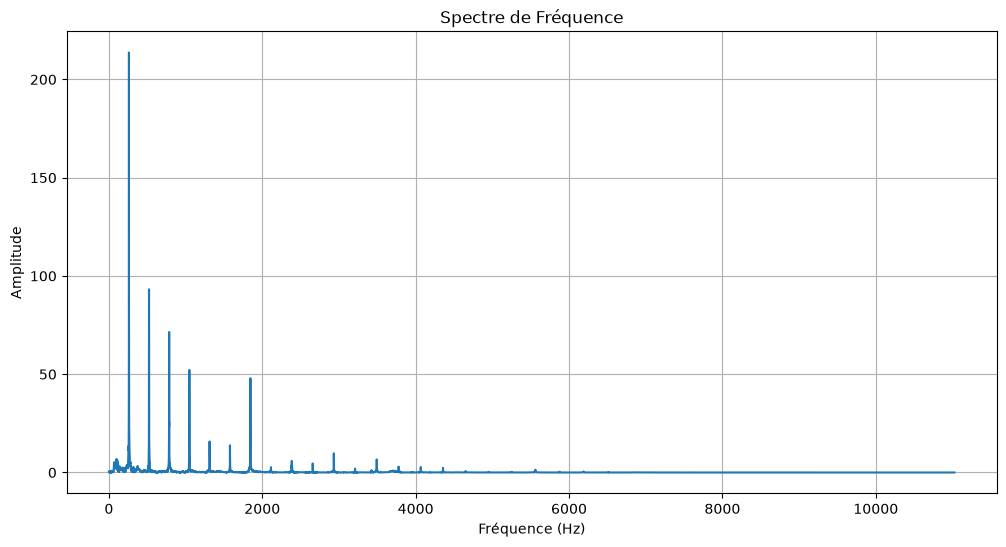

In [ ]:
# Filtrer les fréquences négatives
positive_frequencies = frequencies[:len(frequencies)//2]
positive_magnitude = magnitude[:len(magnitude)//2]


# Affichage du spectre de fréquence
plt.figure(figsize=(12, 6))
plt.plot(positive_frequencies, positive_magnitude)
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

### 3)  Identifier les fréquences dominantes : 
Analyser les résultats de la FFT pour trouver les pics de fréquences correspondant aux notes jouées.

In [ ]:
# Détection des fréquences dominantes
valseuil=0.5
threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
idx=np.where(positive_magnitude > threshold)
peaks = positive_frequencies[positive_magnitude > threshold]

print('Fréquence en Hz :',peaks,'Amplitude :',positive_magnitude[idx])

Fréquence en Hz : [261.56995512] Amplitude : [213.69002]


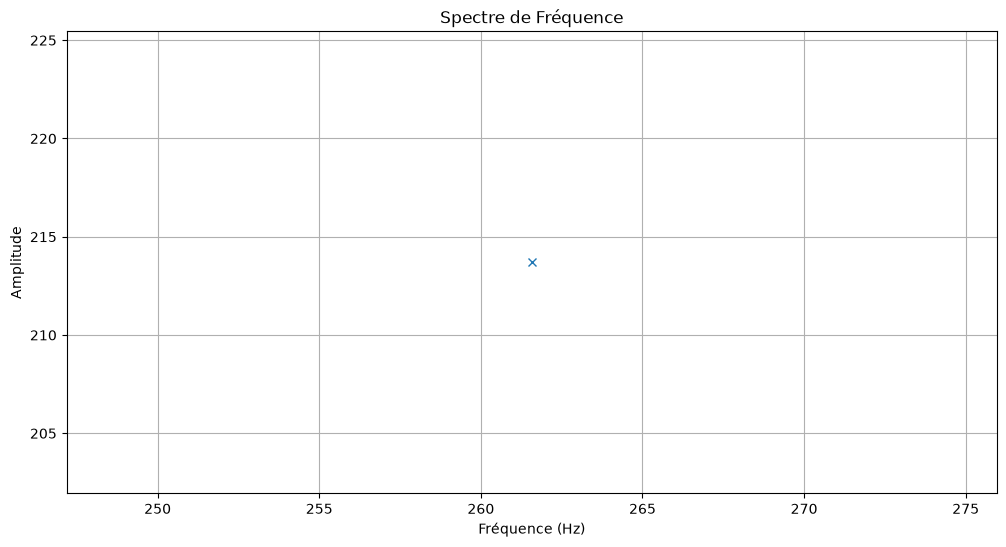

In [ ]:
# Affichage du spectre de fréquence après filtrage
plt.figure(figsize=(12, 6))
plt.plot(peaks, positive_magnitude[idx],'x')
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

### 4) Associer les fréquences aux notes musicales : 
On va utiliser une table de correspondance pour associer les fréquences détectées aux notes musicales.

La formule de base pour calculer les fréquences des notes musicales d’une gamme à tempérament égal :
$$f_n=f_0*2^{n/12}$$

où
- $f_n$ est la fréquence de la note, correspondante aux demi-tons n loin de la hauteur de référence la 440 ;
- $f_0$ est la fréquence d’une note fixe utilisée comme référence pour l’accordage. Il s’agit généralement d’une hauteur de référence de 440 Hz appelée la 440 ou la note le la (la4 ou A4)
- $n$ correspond au numéro des demi-tons de la hauteur de référence ; n > 0 pour les notes supérieures à la hauteur de référence et n < 0 pour les notes inférieures à la hauteur de référence.

Pour calculer les fréquences des notes musicales à partir d’un numéro de note MIDI connu $n_m$ et une hauteur de référence la 440, et vice versa, on peut utiliser ces formules 
$$n_m=12*log_2(\frac{f_n}{440})+69$$
où 69 correspond au numéro de note MIDI de A4 (la4).

In [3]:
# Fonction pour associer une fréquence à une note
def frequency_to_note(freq):
    # Notes de référence (La 4 = 440 Hz)
    A4 = 440
    # Calcul de l'indice de note
    note_number = 12 * np.log2(freq / A4) + 69
    # Table de correspondance des notes
    note_names = ['Do', 'Do#', 'Ré', 'Ré#', 'Mi', 'Fa', 'Fa#', 'Sol', 'Sol#', 'La', 'La#', 'Si']
    note_index = int(round(note_number)) % 12
    octave = int(round(note_number)) // 12 - 1
    return note_names[note_index] + str(octave)


In [ ]:
# Affichage des notes détectées
detected_notes = [frequency_to_note(freq) for freq in peaks if freq > 20]  # On ignore les très basses fréquences
print("Notes détectées :", np.unique(detected_notes))

Notes détectées : ['Do4']


##  5) Reconstitution de la note de musique par Transformée de Fourier inverse



In [ ]:
# Création d'un spectre simplifié pour la synthèse en iFFT    
simplified_fft = np.zeros_like(fft, dtype=complex)
for freq in peaks:
    idx = np.argmin(np.abs(frequencies - freq))
    simplified_fft[idx] = fft[idx]  # On conserve la magnitude de la fréquence dominante

    
# Reconstituer le signal temporel avec l'iFFT
reconstructed_signal = np.fft.ifft(simplified_fft).real


In [ ]:
import soundfile as sf

# Sauvegarder le signal synthétisé en fichier audio
sf.write('synthesized_note_audio.wav',reconstructed_signal, sr)

#print("Le signal synthétisé a été enregistré sous le nom 'synthesized_note_audio.wav'")
IPython.display.Audio('synthesized_note_audio.wav')

# B. Analyse fréquentielle du signal audio avec une fenêtre glissante

Grâce à la première partie, nous pouvons détecter les notes qui ont été jouées. Cependant, l'inconvénient de l'analyse purement fréquentielle est qu'on ne peut pas savoir à quel moment ces notes ont été jouées. Dans la suite, nous allons donc considérer une fenêtre glissante temporelle. 

Pour analyser un fichier audio et reconnaître les notes jouées sur une fenêtre glissante temporelle, nous allons diviser le signal audio en segments ou "fenêtres" de durée fixe, appliquer la transformée de Fourier sur chaque fenêtre, puis identifier les fréquences dominantes dans chaque segment pour déterminer les notes jouées.

### Fenêtrage temporel : 
Diviser le signal en segments avec une durée déterminée (par exemple, 0.1 ou 0.2 secondes) en utilisant une fenêtre glissante.

In [ ]:
# Paramètres de la fenêtre glissante
window_duration = 1  # Durée de la fenêtre en secondes
hop_duration = 1 # Pas de glissement en secondes

#Appliction de ces paramètres au signal
window_size = int(window_duration * sr)  # Taille de la fenêtre en échantillons
hop_size = int(hop_duration * sr)  # Taille du pas en échantillons

In [ ]:
# Initialisation pour stocker les notes détectées
detected_notes = []
filename = 'DoMiSol.mp3'
signal, sr = librosa.load(filename)

# Paramètres de la fenêtre glissante
window_duration = 1  # Durée de la fenêtre en secondes
hop_duration = 1 # Pas de glissement en secondes

#Appliction de ces paramètres au signal
window_size = int(window_duration * sr)  # Taille de la fenêtre en échantillons
hop_size = int(hop_duration * sr)  # Taille du pas en échantillons

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    valseuil=0.5
    threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
    idx=np.where(positive_magnitude > threshold)
    peaks = positive_frequencies[positive_magnitude > threshold]

    print('Fréquence en Hz :',peaks,'Amplitude :',positive_magnitude[idx])

    # Conversion des fréquences en notes et ajout à la liste
    detected_notes.extend(frequency_to_note(freq) for freq in peaks if freq > 20)
print("Notes détectées :", np.unique(detected_notes))
    



Fréquence en Hz : [261.26953125 261.58854167 261.90755208 328.58072917 328.89973958
 329.21875    329.53776042 329.85677083 390.78776042 391.10677083
 391.42578125 391.74479167 392.06380208 392.3828125 ] Amplitude : [367.28186 507.40665 496.63385 371.82938 581.5177  705.64185 632.32074
 438.61102 356.11075 497.771   598.204   613.9443  547.4368  420.1481 ]
Fréquence en Hz : [261.26953125 261.58854167 261.90755208 328.58072917 328.89973958
 329.21875    329.53776042 329.85677083 390.78776042 391.10677083
 391.42578125 391.74479167 392.06380208 392.3828125 ] Amplitude : [367.28186 507.40665 496.63385 371.82938 581.5177  705.64185 632.32074
 438.61102 356.11075 497.771   598.204   613.9443  547.4368  420.1481 ]
Fréquence en Hz : [261.26953125 261.58854167 261.90755208 328.58072917 328.89973958
 329.21875    329.53776042 329.85677083 390.78776042 391.10677083
 391.42578125 391.74479167 392.06380208 392.3828125 ] Amplitude : [367.28186 507.40665 496.63385 371.82938 581.5177  705.64185 632.3

In [ ]:
# Affichage des notes détectées
for i, notes in enumerate(np.unique(detected_notes)):
    print(f"Fenêtre {i+1} : Notes détectées -> {(notes)}")


Fenêtre 1 : Notes détectées -> Do4
Fenêtre 2 : Notes détectées -> Mi4
Fenêtre 3 : Notes détectées -> Sol4


# C. Reconstitution des notes par transformée de Fourier inverse

**Reconstruction du Signal :** Avec l’inverse de Fourier (iFFT), on reconstruit le signal temporel basé sur les fréquences dominantes de chaque fenêtre. On ajoute chaque segment reconstruit dans le tableau synthesized_signal en respectant la position dans le signal global.

In [ ]:
# Création d'un tableau vide pour stocker le signal synthétisé
synthesized_signal = np.zeros(len(signal))

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(window_signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    valseuil=0.5
    threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
    #idx=np.where(positive_magnitude > threshold)
    pdominant_freqseaks = positive_frequencies[positive_magnitude > threshold]

    #print('Fréquence en Hz :',pdominant_freqseaks,'Amplitude :',positive_magnitude[idx])

    # Création d'un spectre simplifié pour la synthèse en iFFT    
    simplified_fft = np.zeros_like(fft, dtype=complex)
    for freq in pdominant_freqseaks:
        idx = np.argmin(np.abs(frequencies - freq))
        simplified_fft[idx] = fft[idx]  # On conserve la magnitude de la fréquence dominante

        
    # Reconstituer le signal temporel avec l'iFFT
    reconstructed_signal = np.fft.ifft(simplified_fft).real
    print(reconstructed_signal)

    # Additionner le signal synthétisé à la position de la fenêtre
    synthesized_signal[start:start + window_size] += reconstructed_signal[:window_size]



[ 0.00415093  0.00585094  0.00753518 ... -0.00061717  0.00087589
  0.00247854]
[-0.01410721 -0.0153067  -0.01637245 ... -0.0098175  -0.01135047
 -0.01278459]
[0.01414913 0.01071402 0.00714468 ... 0.0232338  0.02044814 0.01740733]


In [ ]:
import soundfile as sf

# Sauvegarder le signal synthétisé en fichier audio
sf.write('synthesized_audio.wav', synthesized_signal, sr)

print("Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'")
IPython.display.Audio('synthesized_audio.wav')

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


# Votre étude : points à considérer pour les sons + complexes


A partir du dossier **Enregistrements**, 12 enregistrements (et 5 versions longues) issus de BO de films vous sont proposés. Ces sons étant plus complexes, il vous est par conséquent demandé de réaliser une petite étude sur les paramètres adéquats suivants pour avoir une reconstitution correcte : 

-  **Précision et Bruit :** Le seuil pour détecter les fréquences dominantes (*threshold et valseuil*) peut être ajusté pour améliorer la détection et éviter le bruit.

- **Paramètres de Fenêtre et de Pas :** Ajustez *window_duration* et *hop_duration* pour capturer suffisamment d'information sans perdre les détails des notes jouées rapidement.

Ce travail est à réaliser par **binôme** et il vous sera demandé de rendre le notebook comprenant le code **bien commenté** de votre étude sur au moins 2 enregistrements. 
Des commentaires sur votre étude doit figurer sur la capsule **Vos commentaires sur votre étude**. 

In [6]:
# Votre étude à coder et commenter
#Charger le fichier audio
filename = "C:/Users/Etudiant/OneDrive/Documents/fidel/Projet/programmation_Python/SourcesTP_OutilMath/Enregistrements/Film11.mp3"
import os
print(os.path.exists(filename))
signal, sr = librosa.load(filename)#chargement du fichier audio
# Jouer le son 
IPython.display.Audio(filename)



True


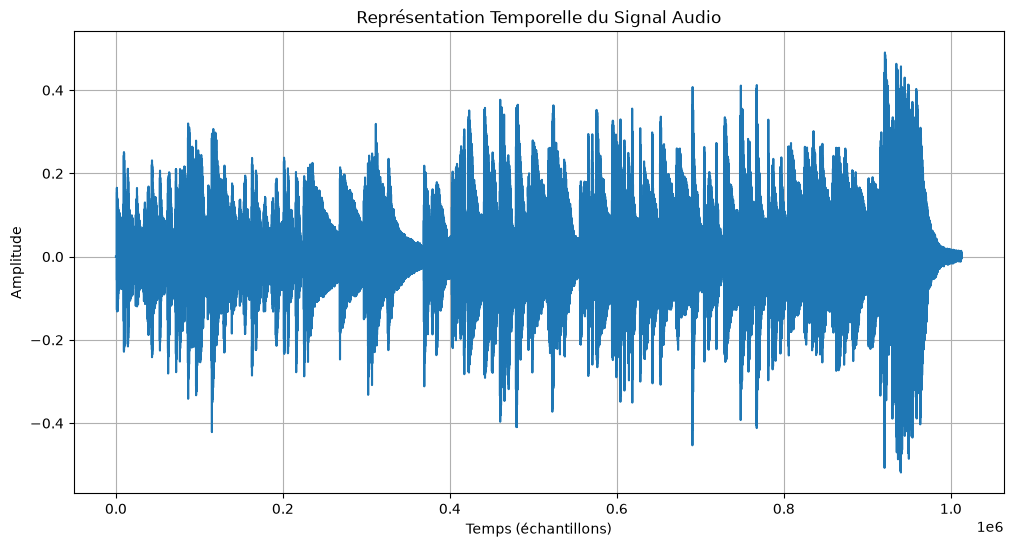

In [7]:
# Affichage de la représentation temporelle du signal audio
plt.figure(figsize=(12, 6))
plt.plot(signal)
plt.title("Représentation Temporelle du Signal Audio")
plt.xlabel("Temps (échantillons)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

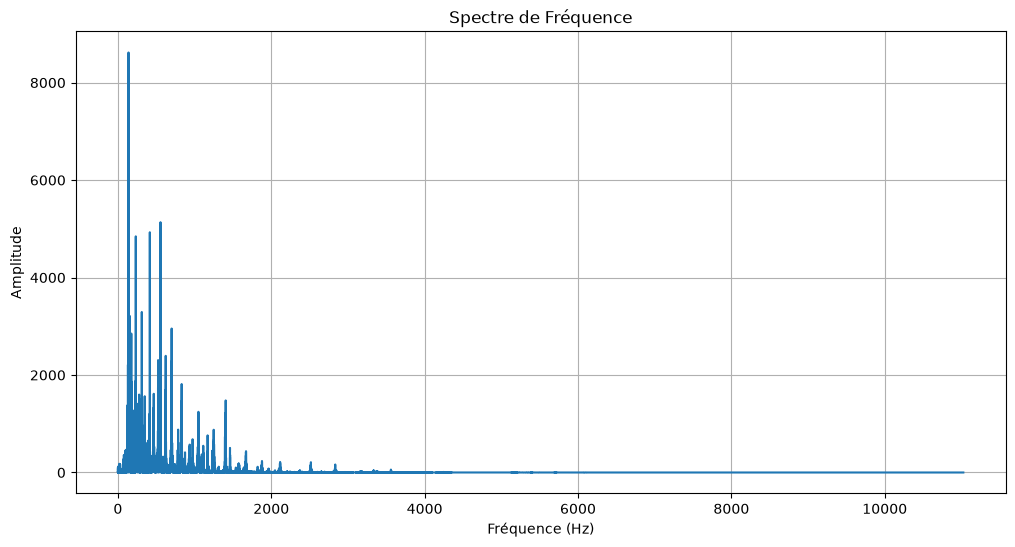

In [8]:
# Calcul de la transformée de Fourier du signal du fichier audio choisi(FFT)
fft = np.fft.fft(signal)
magnitude = np.abs(fft)  # Magnitude de la FFT
frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes


# Filtrer les fréquences négatives 
positive_frequencies = frequencies[:len(frequencies)//2]
positive_magnitude = magnitude[:len(magnitude)//2]


# Affichage du spectre de fréquence
plt.figure(figsize=(12, 6))
plt.plot(positive_frequencies, positive_magnitude)
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

Fréquence en Hz : [138.55722056 138.57899602 138.60077147 138.68787329 138.70964875
 138.7314242  138.9274033  138.99272966 139.14515785 233.17157281
 233.30222554 233.324001   416.52090444 555.66606229] Amplitude : [4468.086  8360.912  4591.292  8618.604  8131.499  5101.04   4540.9146
 5832.8877 6280.0903 4570.315  4445.148  4845.872  4929.75   5135.8965]


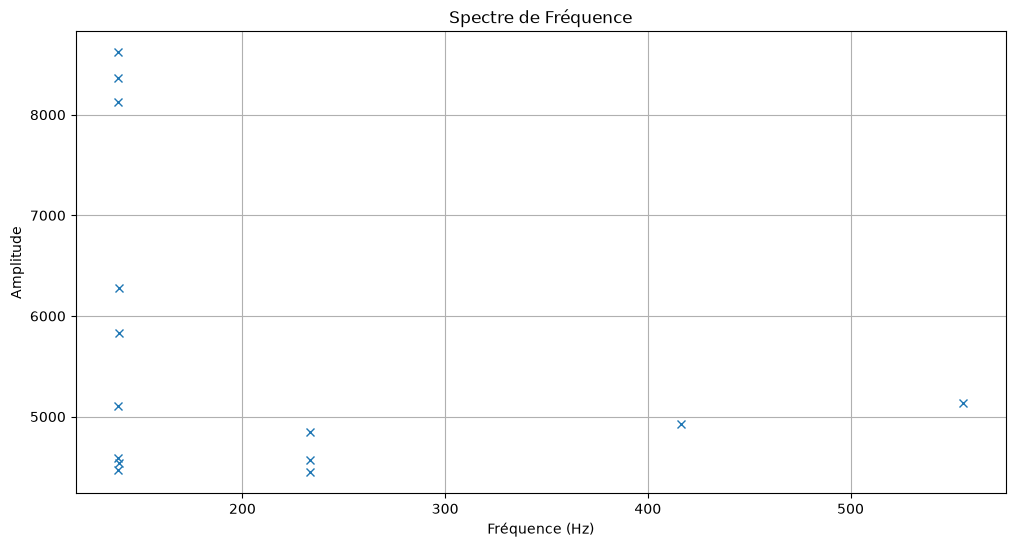

In [9]:
# Détection des fréquences dominantes
valseuil=0.5
threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
idx=np.where(positive_magnitude > threshold)
peaks = positive_frequencies[positive_magnitude > threshold]

print('Fréquence en Hz :',peaks,'Amplitude :',positive_magnitude[idx])

# Affichage du spectre de fréquence après filtrage
plt.figure(figsize=(12, 6))
plt.plot(peaks, positive_magnitude[idx],'x')
plt.title("Spectre de Fréquence")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

In [10]:
detected_notes = []#declaration de la liste des notes détectées
# Paramètres de la fenêtre glissante
window_duration = 1  # Durée de la fenêtre en secondes
hop_duration = 1 # Pas de glissement en secondes


#Appliction de ces paramètres au signal
window_size = int(window_duration * sr)  # Taille de la fenêtre en échantillons
hop_size = int(hop_duration * sr)  # Taille du pas en échantillons

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    valseuil=0.5
    threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
    idx=np.where(positive_magnitude > threshold)
    peaks = positive_frequencies[positive_magnitude > threshold]

    print('Fréquence en Hz :',peaks,'Amplitude :',positive_magnitude[idx])

    # Conversion des fréquences en notes et ajout à la liste
    detected_notes.extend(frequency_to_note(freq) for freq in peaks if freq > 20)
print("Notes détectées :", np.unique(detected_notes))
    


Fréquence en Hz : [138.55722056 138.57899602 138.60077147 138.68787329 138.70964875
 138.7314242  138.9274033  138.99272966 139.14515785 233.17157281
 233.30222554 233.324001   416.52090444 555.66606229] Amplitude : [4468.086  8360.912  4591.292  8618.604  8131.499  5101.04   4540.9146
 5832.8877 6280.0903 4570.315  4445.148  4845.872  4929.75   5135.8965]
Fréquence en Hz : [138.55722056 138.57899602 138.60077147 138.68787329 138.70964875
 138.7314242  138.9274033  138.99272966 139.14515785 233.17157281
 233.30222554 233.324001   416.52090444 555.66606229] Amplitude : [4468.086  8360.912  4591.292  8618.604  8131.499  5101.04   4540.9146
 5832.8877 6280.0903 4570.315  4445.148  4845.872  4929.75   5135.8965]
Fréquence en Hz : [138.55722056 138.57899602 138.60077147 138.68787329 138.70964875
 138.7314242  138.9274033  138.99272966 139.14515785 233.17157281
 233.30222554 233.324001   416.52090444 555.66606229] Amplitude : [4468.086  8360.912  4591.292  8618.604  8131.499  5101.04   4540.

In [11]:
# Création d'un tableau vide pour stocker le signal synthétisé
synthesized_signal = np.zeros(len(signal))

# Itération sur le signal avec une fenêtre glissante
for start in range(0, len(signal) - window_size, hop_size):
    window_signal = signal[start:start + window_size]
    
    # Calcul de la FFT de la fenêtre
    fft = np.fft.fft(window_signal)
    magnitude = np.abs(fft)  # Magnitude de la FFT
    frequencies = np.fft.fftfreq(len(magnitude), 1/sr)  # Fréquences correspondantes
    
    # Filtrage des fréquences négatives
    positive_frequencies = frequencies[:len(frequencies)//2]
    positive_magnitude = magnitude[:len(magnitude)//2]

    # Détection des fréquences dominantes
    valseuil=0.2
    threshold = max(positive_magnitude) * valseuil  # Seuil pour détecter les pics significatifs
    #idx=np.where(positive_magnitude > threshold)
    pdominant_freqseaks = positive_frequencies[positive_magnitude > threshold]

    #print('Fréquence en Hz :',pdominant_freqseaks,'Amplitude :',positive_magnitude[idx])

    # Création d'un spectre simplifié pour la synthèse en iFFT    
    simplified_fft = np.zeros_like(fft, dtype=complex)
    for freq in pdominant_freqseaks:
        idx = np.argmin(np.abs(frequencies - freq))
        simplified_fft[idx] = fft[idx]  # On conserve la magnitude de la fréquence dominante

        
    # Reconstituer le signal temporel avec l'iFFT
    reconstructed_signal = np.fft.ifft(simplified_fft).real
    print(reconstructed_signal)

    # Additionner le signal synthétisé à la position de la fenêtre
    synthesized_signal[start:start + window_size] += reconstructed_signal[:window_size]

[-0.00211123 -0.0025869  -0.00301517 ... -0.00045551 -0.00103924
 -0.00159336]
[0.02437269 0.02560474 0.02656275 ... 0.01905926 0.02110985 0.02287603]
[0.0167329  0.01442826 0.0119986  ... 0.0191534  0.01932377 0.01847028]
[-0.04298609 -0.03950365 -0.03502733 ... -0.04800393 -0.04728763
 -0.04557938]
[-0.03998978 -0.03146689 -0.02244842 ... -0.05776016 -0.05357542
 -0.04751844]


[0.00728121 0.00693469 0.00693675 ... 0.0100336  0.0088803  0.00794447]
[0.018321   0.01733727 0.01661435 ... 0.02222458 0.02083655 0.01950995]
[-0.01540805 -0.01605231 -0.01661003 ... -0.01307396 -0.01390658
 -0.01468877]
[0.02423676 0.02447364 0.02416719 ... 0.02249353 0.02300393 0.02366595]
[ 0.00243034  0.00013593 -0.00108362 ...  0.01155378  0.00860436
  0.00540806]
[-0.02116666 -0.02018565 -0.01919199 ... -0.02405271 -0.02309958
 -0.02213752]
[-0.02628453 -0.02554239 -0.02475977 ... -0.02825678 -0.02764279
 -0.02698503]
[0.00650192 0.00689217 0.00727953 ... 0.00531235 0.00571225 0.00610868]
[-0.00322982 -0.00236176 -0.00185108 ... -0.00772202 -0.00594848
 -0.00443621]
[-0.0283935  -0.02911792 -0.02979658 ... -0.02595755 -0.02681206
 -0.02762447]
[0.00939788 0.00868293 0.00795421 ... 0.01144903 0.01078202 0.01009794]
[ 0.00217917 -0.0010056  -0.00309296 ...  0.01360955  0.01000862
  0.00602388]
[0.01664582 0.0165131  0.01568968 ... 0.01327419 0.01495863 0.01610984]
[-0.02395665 -0

In [12]:
import soundfile as sf

# Sauvegarder le signal synthétisé en fichier audio
sf.write('synthesized_audio.wav', synthesized_signal, sr)

print("Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'")
IPython.display.Audio('synthesized_audio.wav')

Le signal synthétisé a été enregistré sous le nom 'synthesized_audio.wav'


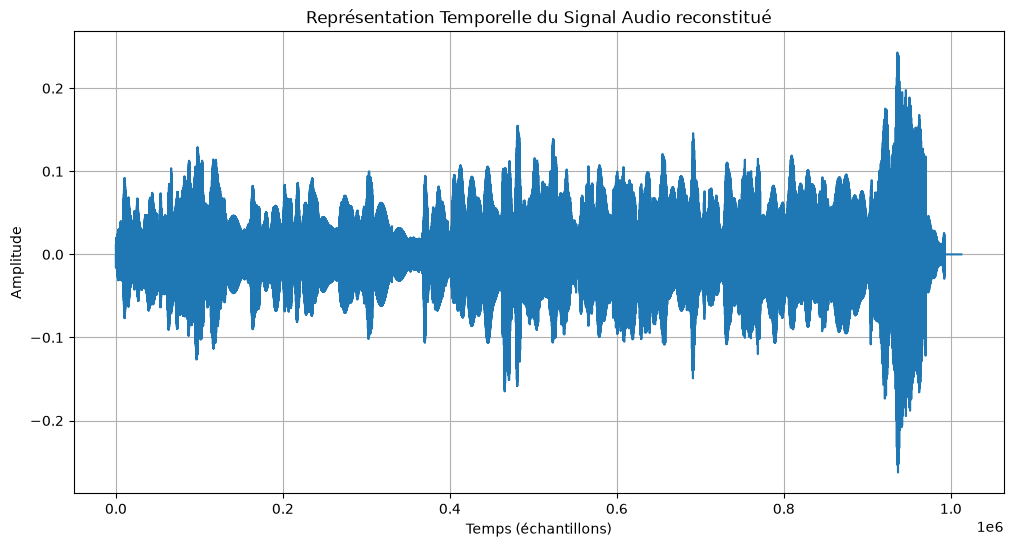

In [13]:
# Affichage de la représentation temporelle du signal audio reconstitué
plt.figure(figsize=(12, 6))
plt.plot(synthesized_signal)
plt.title("Représentation Temporelle du Signal Audio reconstitué")
plt.xlabel("Temps (échantillons)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# Vos Commentaires sur l'étude

Commenter votre étude pour chaque enregistrement et les résultats obtenus. 


# Pour aller plus loin : principes de l'empreinte sonore et de l'application Shazam 



Vous avez recherché, pour chaque mesure, les $n$ fréquences correspondant aux $n$ plus grandes valeurs du module du spectre. Avec un nombre $n$ suffisant, vous avez constaté qu’il était possible de restituer un signal sonore quasiment identique à l’original. 

Le **spectrogramme** est ainsi une représentation caractéristique d’un enregistrement musical. Mais il contient beaucoup d’informations redondantes. Il est alors possible d’extraire à partir de cette représentation des « signatures » ou « empreintes » des morceaux de musique un peu à l’image des empreintes digitales pour l’identification de personnes. Les systèmes de reconnaissance musicale permettent ainsi de comparer la signature d’un morceau de musique inconnu à l’ensemble des signatures préalablement calculées et stockées dans une base de données.


Mais il est possible de détecter encore moins de fréquences par mesure, si le but n’est pas de restituer le son original, mais de produire une « marque », appelée **empreinte sonore**, qui puisse caractériser un morceau de musique de manière unique comme le montre la figure suivante.


<img src="./EmpreinteSonore.png" width="1000" height="800">



L’**application Shazam** détecte $n = 6$ fréquences seulement par mesure. Mais au lieu de chercher ces fréquences dans la bande $[f_{min}, f_{max}]$, elle découpe cette bande en $n = 6$ sous-bandes, et cherche dans chaque sous-bande la fréquence correspondant à la plus grande valeur du module du spectre.

La création d’**une base d’empreintes sonores** consiste à numériser un certain nombre de morceaux de musique (la base de l’application Shazam est gigantesque) servant par la suite à une méthode d'apprentissage automatique pour réaliser le reconnaissance du morceau musical. 
